# PY-1 · Independent validation and root-cause analysis

**Question:** Leadership believes service performance is improving. Is it, what changed between Jan–Apr and May–Jun, and why?

This notebook:
1. Rebuilds the cleaned dataset **from the original Excel file with pandas**, separately from the SQL pipeline, and checks **five** SQL results against it.
2. Tests seven plausible explanations for the change, one at a time.
3. Separates what the data shows (association) from what it cannot prove (causation).

Shared logic lives in `python/tcu_common.py`. SQL results are read from `outputs/sql/` (produced by `run_sql.py`).

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from scipy import stats

warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "python"))
import tcu_common as tc

SQL_OUT = ROOT / "outputs" / "sql"
FIG = ROOT / "outputs" / "python"; FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)

# chart style: one accent for the hot spot, neutral for everything else
BLUE, ORANGE, GRAY, INK, MUTED = "#2a78d6", "#eb6834", "#9a9893", "#0b0b0b", "#52514e"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#c3c2b7", "axes.labelcolor": MUTED, "xtick.color": MUTED,
                     "ytick.color": MUTED, "axes.grid": True, "grid.color": "#ecebe7",
                     "grid.linewidth": 0.8, "axes.titleweight": "bold", "axes.titlesize": 11,
                     "font.size": 9.5, "lines.linewidth": 2, "axes.axisbelow": True, "axes.grid.axis": "y"})

raw = tc.load_raw(ROOT / "data" / "BI_Analyst_Round_1_Technical_Assessment.xlsx")
assert not tc.check_schema(raw), tc.check_schema(raw)
a, dq = tc.clean(raw)
print(f"Analysis rows: {len(a):,}  |  members: {a.member_id.nunique()}  |  "
      f"{a.interaction_date.min():%Y-%m-%d} to {a.interaction_date.max():%Y-%m-%d}")
pd.Series(dq, name="count").to_frame()

Analysis rows: 3,992  |  members: 400  |  2026-01-01 to 2026-06-30


,count
raw_interaction_rows,4004
raw_member_rows,400
duplicate_id_rows_extra,12
exact_duplicate_rows,12
conflicting_duplicate_ids,0
channel_recoded_rows,8
channel_unmapped_rows,0
wait_missing_rows,7
satisfaction_missing_rows,2890
abandoned_with_handle_time,194


## Part 1 · Independent validation of SQL results

Each check compares the pandas result with the SQL output CSV. The tolerance equals the SQL rounding (for example, a rate rounded to 3 decimals can differ by up to 0.0005).

In [2]:
results = []
def check(name, sql_value, py_value, tol=0.0):
    diff = abs(float(sql_value) - float(py_value))
    results.append({"check": name, "sql": sql_value, "python": round(float(py_value), 4),
                    "abs_diff": round(diff, 4), "status": "MATCH" if diff <= tol + 1e-9 else "DIFFERENT"})

# V1 - data-quality counts (SQL issue log)
log = pd.read_csv(SQL_OUT / "01_profile_and_clean__b1_dq_issue_log.csv").set_index("issue_no")
check("V1 duplicates removed",          log.loc[1, "rows_affected"], dq["exact_duplicate_rows"])
check("V1 channel values recoded",      log.loc[2, "rows_affected"], dq["channel_recoded_rows"])
check("V1 missing wait",                log.loc[3, "rows_affected"], dq["wait_missing_rows"])
check("V1 missing satisfaction",        log.loc[4, "rows_affected"], dq["satisfaction_missing_rows"])
check("V1 censored repeat-window rows", log.loc[7, "rows_affected"], (a.repeat_window_complete == 0).sum())

# V2 - monthly KPI table, every cell
k_py = tc.kpis(a, "month").set_index("month")
k_sql = pd.read_csv(SQL_OUT / "02_monthly_kpis__k1_monthly_kpis.csv").set_index("month")
tol = {c: (0.05 if c.endswith("_s") or c in ("p90_wait_s",) else 0.0005) for c in k_sql.columns}
tol.update({"p90_wait_s": 0.5, "avg_satisfaction": 0.005, "contacts_per_member": 0.005,
            "cost_per_resolved": 0.005, "total_est_cost": 0.005, "interactions": 0,
            "unique_members": 0, "survey_responses": 0, "repeat_eligible_contacts": 0})
cell_diffs = (k_py[k_sql.columns].astype(float) - k_sql.astype(float)).abs()
breaches = (cell_diffs.gt(pd.Series(tol) + 1e-9)).sum().sum()
check("V2 monthly KPI cells outside rounding tolerance (120 cells)", 0, breaches)

# V3 - 7-day repeat rate by period (requested metric, window logic re-implemented)
p_sql = pd.read_csv(SQL_OUT / "02_monthly_kpis__k1b_period_kpis.csv").set_index("period")
p_py = a[a.repeat_window_complete == 1].groupby("period").is_repeat_7d.mean()
for p in p_py.index:
    check(f"V3 7-day repeat rate {p}", p_sql.loc[p, "repeat_7d_rate"], p_py[p], 0.0005)

# V4 - hot-spot isolation table (SQL-3 s5)
s5 = pd.read_csv(SQL_OUT / "03_period_drivers__s5_hotspot_isolated.csv")
hs = a[a.hotspot == 1].groupby("period").agg(w=("wait_seconds", "mean"), ab=("is_abandoned", "mean"))
for p in hs.index:
    row = s5[(s5.group_name.str.startswith("A)")) & (s5.period == p)].iloc[0]
    check(f"V4 hot-spot avg wait {p}", row.avg_wait_s, hs.loc[p, "w"], 0.05)
    check(f"V4 hot-spot abandonment {p}", row.abandonment_rate, hs.loc[p, "ab"], 0.0005)

# V5 - contribution decomposition (Phone share of the wait change, SQL-3 s2)
s2 = pd.read_csv(SQL_OUT / "03_period_drivers__s2_driver_contributions_ranked.csv")
sql_phone = s2.query("metric == 'Avg wait (s)' and dimension == 'Channel' and dim_value == 'Phone'").iloc[0]
py_dec = tc.contribution(a, "channel", "wait_seconds")
check("V5 Phone contribution to wait change (s)", sql_phone.contribution_to_total_change,
      py_dec.loc["Phone", "contribution"], 0.00005)
check("V5 decomposition sums to total change (s)", sql_phone.total_change,
      py_dec.contribution.sum(), 0.00005)

validation = pd.DataFrame(results)
validation.to_csv(FIG / "py1_validation_results.csv", index=False)
print(f"{(validation.status == 'MATCH').sum()} of {len(validation)} checks match")
validation

14 of 14 checks match


,check,sql,python,abs_diff,status
0,V1 duplicates removed,12.0000,12.0000,0.0000,MATCH
1,V1 channel values recoded,8.0000,8.0000,0.0000,MATCH
2,V1 missing wait,7.0000,7.0000,0.0000,MATCH
3,V1 missing satisfaction,2890.0000,2890.0000,0.0000,MATCH
4,V1 censored repeat-window rows,184.0000,184.0000,0.0000,MATCH
5,V2 monthly KPI cells outside rounding toleranc...,0.0000,0.0000,0.0000,MATCH
6,V3 7-day repeat rate 1) Jan-Apr,0.3260,0.3258,0.0002,MATCH
7,V3 7-day repeat rate 2) May-Jun,0.3940,0.3939,0.0001,MATCH
8,V4 hot-spot avg wait 1) Jan-Apr,51.4000,51.4218,0.0218,MATCH
9,V4 hot-spot abandonment 1) Jan-Apr,0.0290,0.0294,0.0004,MATCH


**Differences between SQL and Python.** None beyond rounding. Two things needed care to match:
- **P90 wait** uses linear interpolation in both tools (`QUANTILE_CONT` in DuckDB, the default in pandas). If a different quantile method were used (for example, nearest-rank), P90 would differ by a few seconds.
- **AHT** must exclude abandoned contacts in both. The sensitivity check below shows the effect of including them.

In [3]:
aht_incl = a.groupby("month").handle_seconds.mean()
aht_excl = a[a.is_abandoned == 0].groupby("month").handle_seconds.mean()
pd.DataFrame({"AHT excl. abandoned (reported)": aht_excl.round(1),
              "AHT incl. abandoned": aht_incl.round(1),
              "difference (s)": (aht_incl - aht_excl).round(1)})

,AHT excl. abandoned (reported),AHT incl. abandoned,difference (s)
month,,,
2026-01,415.1,414.7,-0.4
2026-02,421.3,420.3,-1.1
2026-03,422.0,422.2,0.2
2026-04,416.7,416.9,0.2
2026-05,432.7,433.9,1.2
2026-06,435.4,438.1,2.7


## Part 2 · Root-cause analysis

Starting point (from SQL-2 and SQL-3): in May–Jun, average wait rose 37s → 54s, abandonment rose 3.6% → 6.9%, resolution fell 80.4% → 77.7%, 7-day repeat rose 32.6% → 39.4%, and volume rose 28%. Each hypothesis below is tested against the data.

### H1 · Is it simply more volume overwhelming the whole operation?

In [4]:
h1 = (a.assign(group=np.select([a.hotspot == 1, a.channel == "Phone"],
                               ["Phone: Credit Card or Payment", "Phone: all other"], "Digital / Chat / Branch"))
        .groupby(["group", "period"])
        .agg(contacts=("interaction_id", "size"), avg_wait=("wait_seconds", "mean"))
        .unstack("period"))
months = {"1) Jan-Apr": 4, "2) May-Jun": 2}
h1[("per_month", "Jan-Apr")] = h1[("contacts", "1) Jan-Apr")] / 4
h1[("per_month", "May-Jun")] = h1[("contacts", "2) May-Jun")] / 2
h1[("growth", "volume %")] = (h1[("per_month", "May-Jun")] / h1[("per_month", "Jan-Apr")] - 1) * 100
h1[("growth", "wait %")] = (h1[("avg_wait", "2) May-Jun")] / h1[("avg_wait", "1) Jan-Apr")] - 1) * 100
h1.round(1)

contacts              avg_wait            per_month           growth       
period                        1) Jan-Apr 2) May-Jun 1) Jan-Apr 2) May-Jun   Jan-Apr May-Jun volume % wait %
group                                                                                                      
Digital / Chat / Branch             1223        786       23.5       24.6     305.8   393.0     28.5    5.0
Phone: Credit Card or Payment        442        292       51.4      136.8     110.5   146.0     32.1  166.0
Phone: all other                     772        477       50.6       50.3     193.0   238.5     23.6   -0.5

**Finding.** Volume grew in all three groups by a similar amount (+24% to +32% per month). Only the Phone **Credit Card / Payment** group saw wait increase, by about +166%. Other phone contacts absorbed +24% volume with **no change** in wait. General volume pressure does not explain it. Something specific to the queue that handles card and payment calls does.

### H2 · Is one team responsible?

In [5]:
h2 = a[a.hotspot == 1].pivot_table(index="team", columns="period", values="wait_seconds", aggfunc="mean").round(1)
h2["change_s"] = h2.iloc[:, 1] - h2.iloc[:, 0]
h2

period,1) Jan-Apr,2) May-Jun,change_s
team,,,
Alpha,53.8,133.5,79.7
Bravo,52.0,136.8,84.8
Charlie,48.2,137.0,88.8
Delta,51.6,139.7,88.1


**Finding.** No. All four teams went from about 50s to about 135–140s on these contacts. This looks like a queue, routing or capacity issue, not an individual team performance issue. That matters for who owns the fix.

### H3 · Did the member mix change (segment, region, tenure, digital adoption)?

In [6]:
model_df = a.dropna(subset=["wait_seconds"]).copy()
model_df["may_jun"] = (model_df.period == "2) May-Jun").astype(int)
m_raw = smf.ols("wait_seconds ~ hotspot * may_jun", data=model_df).fit(cov_type="HC1")
m_ctl = smf.ols("wait_seconds ~ hotspot * may_jun + C(channel) + C(segment) + C(region) + C(tenure_band)"
                " + C(digital_adoption_band) + C(team) + products_held", data=model_df).fit(cov_type="HC1")
h3 = pd.DataFrame({
    "hot-spot x May-Jun effect (s), no controls": [m_raw.params["hotspot:may_jun"], *m_raw.conf_int().loc["hotspot:may_jun"]],
    "hot-spot x May-Jun effect (s), with member/team/channel controls": [m_ctl.params["hotspot:may_jun"], *m_ctl.conf_int().loc["hotspot:may_jun"]],
}, index=["estimate", "95% CI low", "95% CI high"]).T.round(1)
mix = pd.concat({d: tc.contribution(a, d, "wait_seconds")[["mix_effect"]].sum()
                 for d in ["segment", "region", "tenure_band", "digital_adoption_band"]}).unstack().round(2)
display(h3)
print("Mix effect on the +16.5s overall wait change, by member dimension (s):")
mix

,estimate,95% CI low,95% CI high
"hot-spot x May-Jun effect (s), no controls",85.0,79.7,90.2
"hot-spot x May-Jun effect (s), with member/team/channel controls",85.2,80.1,90.3


Mix effect on the +16.5s overall wait change, by member dimension (s):


,mix_effect
segment,0.05
region,-0.02
tenure_band,-0.00
digital_adoption_band,0.04


**Finding.** No. Adding every member, team and channel control leaves the extra wait on hot-spot contacts at about +85s, with a tight confidence interval. Member-mix effects contribute under 0.5s of the 16.5s overall increase.

### H4 · When did it change? (step change or gradual drift)

Best single change point: 2026-05-01  |  mean before 51s -> after 138s


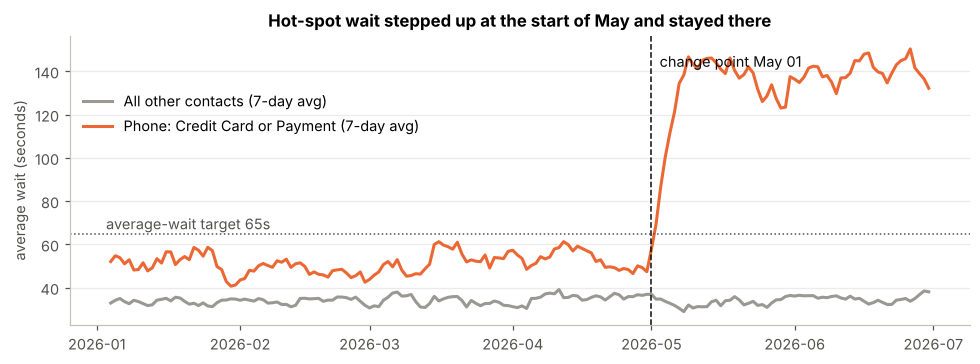

In [7]:
daily = (a[a.hotspot == 1].groupby("interaction_date").wait_seconds.mean().asfreq("D"))
d = daily.dropna()
# simple change-point search: the split date that minimizes total squared error of two flat means
sse = {}
for t in d.index[14:-14]:
    left, right = d[d.index < t], d[d.index >= t]
    sse[t] = ((left - left.mean())**2).sum() + ((right - right.mean())**2).sum()
cp = min(sse, key=sse.get)
before, after = d[d.index < cp].mean(), d[d.index >= cp].mean()
print(f"Best single change point: {cp:%Y-%m-%d}  |  mean before {before:.0f}s -> after {after:.0f}s")

other = a[a.hotspot == 0].groupby("interaction_date").wait_seconds.mean()
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(other.rolling(7, min_periods=4).mean(), color=GRAY, label="All other contacts (7-day avg)")
ax.plot(daily.rolling(7, min_periods=4).mean(), color=ORANGE, label="Phone: Credit Card or Payment (7-day avg)")
ax.axvline(cp, color=INK, lw=1, ls="--"); ax.text(cp, ax.get_ylim()[1]*0.95, f"  change point {cp:%b %d}", color=INK, va="top")
ax.axhline(65, color=MUTED, lw=1, ls=":"); ax.text(daily.index[2], 67, "average-wait target 65s", color=MUTED)
ax.set_ylabel("average wait (seconds)"); ax.set_title("Hot-spot wait stepped up at the start of May and stayed there")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, 0.85)); fig.tight_layout()
fig.savefig(FIG / "py1_h4_change_point.png", dpi=150, metadata={"Software": None}); plt.show()

**Finding.** It was a **step change** at the start of May, not a gradual drift, and it has not recovered. Step changes usually come from a discrete event: a staffing or schedule change, an IVR or routing change, a card-platform or payment-system incident, or a policy change. The data cannot say which, so this is the first question for Operations.

### H5 · Does long wait drive the other outcomes? (dose-response)

,contacts,abandonment,resolution,satisfaction,survey_n
wait_band,,,,,
0-30,1867,0.041,0.799,2.854,520
31-60,1095,0.024,0.800,2.756,308
61-90,644,0.042,0.815,2.655,174
91-120,177,0.079,0.808,2.778,45
121-150,92,0.239,0.641,2.304,23
150+,110,0.255,0.627,1.710,31


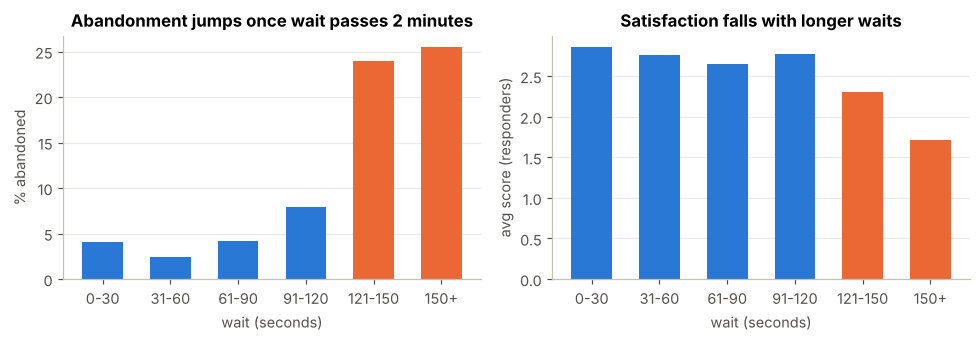

Abandonment, wait >120s vs <=120s: chi-square p = 1.6e-40


In [8]:
bins = [-1, 30, 60, 90, 120, 150, 400]
labels = ["0-30", "31-60", "61-90", "91-120", "121-150", "150+"]
h5 = (a.dropna(subset=["wait_seconds"]).assign(wait_band=lambda x: pd.cut(x.wait_seconds, bins, labels=labels))
        .groupby("wait_band", observed=True)
        .agg(contacts=("interaction_id", "size"), abandonment=("is_abandoned", "mean"),
             resolution=("is_resolved", "mean"), satisfaction=("satisfaction", "mean"),
             survey_n=("has_survey", "sum")))
display(h5.round(3))
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
axes[0].bar(h5.index.astype(str), h5.abandonment * 100, color=[BLUE]*4 + [ORANGE]*2, width=0.6)
axes[0].set_title("Abandonment jumps once wait passes 2 minutes"); axes[0].set_ylabel("% abandoned"); axes[0].set_xlabel("wait (seconds)")
axes[1].bar(h5.index.astype(str), h5.satisfaction, color=[BLUE]*4 + [ORANGE]*2, width=0.6)
axes[1].set_title("Satisfaction falls with longer waits"); axes[1].set_ylabel("avg score (responders)"); axes[1].set_xlabel("wait (seconds)")
fig.tight_layout(); fig.savefig(FIG / "py1_h5_dose_response.png", dpi=150, metadata={"Software": None}); plt.show()
chi = stats.chi2_contingency(pd.crosstab(a.wait_seconds > 120, a.is_abandoned))
print(f"Abandonment, wait >120s vs <=120s: chi-square p = {chi.pvalue:.1e}")

**Finding.** There is a clear threshold. Abandonment stays around 2–8% up to 120s, then jumps to about 24–25%. Resolution falls from about 80% to about 63%, and satisfaction falls with wait. This is consistent with long wait **causing** abandonment (the timing and dose-response both fit), but other explanations are possible: for example, harder issues might both wait longer and be abandoned more. PY-2 models this threshold.

### H6 · Is the rise in 7-day repeat contacts really "failure demand"?

In [9]:
def repeat_rate(df):
    df = df.sort_values(["member_id", "interaction_date", "interaction_id"])
    nxt = df.groupby("member_id").interaction_date.shift(-1)
    ok = df.interaction_date <= pd.Timestamp("2026-06-23")
    return ((nxt - df.interaction_date).dt.days <= 7)[ok].groupby(df.period[ok]).mean()

observed = repeat_rate(a)
rng = np.random.default_rng(42)
spans = {"1) Jan-Apr": ("2026-01-01", 120), "2) May-Jun": ("2026-05-01", 61)}
sims = []
for _ in range(200):     # keep each member's contact COUNT, randomize the DATES within the period
    b = a[["member_id", "interaction_id", "period"]].copy()
    b["interaction_date"] = [pd.Timestamp(spans[p][0]) + pd.Timedelta(days=int(rng.integers(0, spans[p][1]))) for p in b.period]
    sims.append(repeat_rate(b))
sims = pd.concat(sims, axis=1)
h6 = pd.DataFrame({"observed": observed, "random-timing baseline": sims.mean(axis=1),
                   "baseline 95% range low": sims.quantile(0.025, axis=1),
                   "baseline 95% range high": sims.quantile(0.975, axis=1)})
h6["excess over baseline (pts)"] = (h6.observed - h6["random-timing baseline"]) * 100
display(h6.round(3))
same = a[a.repeat_window_complete == 1].groupby("period").is_same_reason_repeat_7d.mean()
print("Same-reason 7-day repeat:", same.round(3).to_dict())

,observed,random-timing baseline,baseline 95% range low,baseline 95% range high,excess over baseline (pts)
period,,,,,
1) Jan-Apr,0.326,0.322,0.307,0.333,0.424
2) May-Jun,0.394,0.376,0.358,0.395,1.753


Same-reason 7-day repeat: {'1) Jan-Apr': 0.061, '2) May-Jun': 0.085}


**Finding (not requested, but important).** The headline "7-day repeat" metric is mostly a **frequency effect**. If each member kept the same number of contacts but those contacts fell on **random dates**, the repeat rate would still be about 32% in Jan–Apr and about 38% in May–Jun. Observed Jan–Apr is at the random baseline. Only about 1–2 points in May–Jun are excess. Most of the "rise in repeats" therefore comes from members contacting more often overall, which in turn ties to the volume growth.

The **same-reason** repeat rate (about 6% → 8.5%) is the better signal of unresolved issues, and it did rise, by about 40%. **Recommendation:** report the same-reason version as the leadership metric. The any-reason version mostly restates volume.

### H7 · Can the satisfaction score be trusted as a measure of member experience?

In [10]:
resp = a.groupby("has_survey").agg(contacts=("interaction_id", "size"), avg_wait=("wait_seconds", "mean"),
                                   resolution=("is_resolved", "mean"), abandonment=("is_abandoned", "mean"))
resp.index = ["No survey", "Survey response"]
display(resp.round(3))
dist = a.satisfaction.value_counts(normalize=True).sort_index()
print("Score distribution among responders:", (dist * 100).round(1).to_dict())
print(f"Response rate: {a.has_survey.mean():.1%}; resolved avg {a.loc[a.is_resolved==1,'satisfaction'].mean():.2f} "
      f"vs not resolved {a.loc[a.is_resolved==0,'satisfaction'].mean():.2f}")

,contacts,avg_wait,resolution,abandonment
No survey,2890,43.681,0.799,0.048
Survey response,1102,43.103,0.780,0.049


Score distribution among responders: {1.0: 26.4, 2.0: 21.1, 3.0: 19.5, 4.0: 17.2, 5.0: 15.7}
Response rate: 27.6%; resolved avg 2.96 vs not resolved 2.00


**Finding.** Responders look like non-responders on wait and outcome, so the score is not obviously skewed toward one kind of contact. However:
- Only about 28% of contacts have a score, which gives roughly 160–220 responses a month and a margin of error of about ±0.2.
- The most common score is **1**, and the average (about 2.7) sits about 1.5 points below a 4.2 target in **every** month.

A gap that large and that constant suggests a **scale or survey-method mismatch**, such as reversed scale direction in part of the survey or a target set on a different instrument. A real service failure would not usually look so flat. Satisfaction should not be used for decisions until its definition is confirmed. Its **direction** is still useful: lower after unresolved contacts and longer waits.

## Part 3 · Association vs causation

| Statement | Evidence level |
|---|---|
| The deterioration is concentrated in Phone contacts about Credit Card or Payment, starting early May | **Established** (descriptive, robust to controls) |
| It is not explained by volume growth alone, team, or member mix | **Strongly supported** (H1–H3 rule these out in this data) |
| Long waits (>2 min) cause higher abandonment and lower resolution | **Plausible causal**: dose-response and timing fit, but not proven without operational data or an experiment |
| The *cause* of the May step change (staffing, routing, system incident, policy) | **Unknown**: needs workforce, IVR/ACD and incident logs |
| Repeat contacts rose because issues were not fixed | **Mostly not supported**: most of the rise is a contact-frequency effect (H6); same-reason repeats rose modestly |
| Members are dissatisfied (2.7 vs 4.2 target) | **Not supported** until survey scale and method are confirmed (H7) |

In [11]:
summary = pd.DataFrame([
    ("H1 Volume overwhelmed operation", "Rejected", "Other phone +24% volume, wait flat; hot spot +32% volume, wait +166%"),
    ("H2 One team", "Rejected", "All 4 teams ~50s -> ~135-140s on hot-spot contacts"),
    ("H3 Member mix", "Rejected", "Hot-spot effect ~+85s with all controls; mix < 0.5s"),
    ("H4 Timing", "Step change", f"Change point {cp:%Y-%m-%d}; {before:.0f}s -> {after:.0f}s, no recovery"),
    ("H5 Wait drives outcomes", "Supported (association)", "Abandonment ~3-8% below 120s, ~24% above"),
    ("H6 Repeats = failure demand", "Mostly rejected", "Any-reason repeat ~ random-timing baseline; same-reason up ~40%"),
    ("H7 CSAT reliable", "Not reliable for targets", "28% response, ~1.5 pts below target every month"),
], columns=["hypothesis", "verdict", "evidence"])
summary.to_csv(FIG / "py1_hypothesis_summary.csv", index=False)
summary

,hypothesis,verdict,evidence
0,H1 Volume overwhelmed operation,Rejected,"Other phone +24% volume, wait flat; hot spot +..."
1,H2 One team,Rejected,All 4 teams ~50s -> ~135-140s on hot-spot cont...
2,H3 Member mix,Rejected,Hot-spot effect ~+85s with all controls; mix <...
3,H4 Timing,Step change,"Change point 2026-05-01; 51s -> 138s, no recovery"
4,H5 Wait drives outcomes,Supported (association),"Abandonment ~3-8% below 120s, ~24% above"
5,H6 Repeats = failure demand,Mostly rejected,Any-reason repeat ~ random-timing baseline; sa...
6,H7 CSAT reliable,Not reliable for targets,"28% response, ~1.5 pts below target every month"
